# Track B: Predicting Risky Choices
**IML Midterm Project, CS-3410 / MAT-3211-1, Ashoka University**  
Name: *Kanchan Bharti* | Kaggle username: *kanchanbharti039*

**Note:** the data is *simulated*.

## Research question
Do framing (gain/loss frame) and features based on expected value help predict risky choices for **new participants**, compared with using only the problem numbers?

## What I expect (hypotheses)
1. **Exp 1:** Adding frame/domain and expected-value features will improve AUC. Person details (age, numeracy, risk score) will not help much for new people.
2. **Exp 2:** A random split will give a higher (too optimistic) AUC than a split by participant, especially if the model can recognise a person.
3. **Exp 3:** `response_time_ms` is recorded *with* the choice, so I will leave it out of my model. I expect it adds nothing anyway.

## Plan
- Metric: **ROC-AUC** (also log-loss and accuracy).
- Validation: `GroupKFold` on `participant_id`, because the test set has people not seen in training.
- Drop `realised_payout_inr` (leakage).
- Only classical ML (no neural networks).
- AI declaration: *Used Claude*

## Evaluation metric: ROC-AUC (what the Kaggle competition scores)
The competition compares my `chose_risky` column with the hidden true answers using **ROC-AUC**.

- The model outputs a **probability** (0 to 1) of choosing risky for each decision.
- ROC-AUC = the chance that a randomly picked *risky* decision gets a **higher** predicted probability than a randomly picked *safe* decision.
- **0.5** = random guessing, **1.0** = perfect ranking. Higher is better.

I also report **log-loss** (how good the probabilities are; lower is better) and **accuracy at a 0.5 threshold** as secondary metrics.

## 1. Load the data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import LinearSVC
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import GroupKFold, KFold, cross_val_predict
from sklearn.metrics import roc_auc_score, log_loss, accuracy_score, roc_curve

import sklearn
np.random.seed(0)   # fixed seed
print("pandas", pd.__version__, "| numpy", np.__version__, "| sklearn", sklearn.__version__)

folder = r"C:\Users\Lenvo\Downloads\iml-2026-track-b-risky-choice"
train = pd.read_csv(folder + r"\train.csv")
test = pd.read_csv(folder + r"\test.csv")
sample = pd.read_csv(folder + r"\sample_submission.csv")
print(train.shape, test.shape)
train.head()

pandas 2.3.3 | numpy 2.2.6 | sklearn 1.7.2
(8400, 18) (3600, 16)


,decision_id,participant_id,trial_index,session_type,age_years,numeracy_score,self_reported_risk_taking,problem_domain,frame,time_pressure,endowment_inr,prob_high,risky_high_inr,risky_low_inr,sure_amount_inr,response_time_ms,realised_payout_inr,chose_risky
0,B00002,S299,28,hypothetical,20,7,7,loss,none,0,200,0.05,0,-200.0,-180,465,NaN,0
1,B00003,S020,10,hypothetical,22,7,2,loss,none,1,1000,0.10,-200,-1000.0,-970,951,NaN,1
2,B00004,S144,16,paid,23,0,4,loss,none,0,1000,0.10,0,-1000.0,-730,429,0.0,1
3,B00005,S085,24,paid,19,4,1,gain,loss_frame,0,600,0.50,0,-600.0,-370,1007,230.0,0
4,B00006,S278,33,hypothetical,23,6,5,gain,loss_frame,0,400,0.75,0,-400.0,-210,683,NaN,1


## 2. Check the data and remove leakage

In [2]:
print("Columns only in train:", set(train.columns) - set(test.columns))
print("Missing values in train:")
print(train.isna().sum()[train.isna().sum() > 0])
print("Train participants:", train.participant_id.nunique(), "| Test participants:", test.participant_id.nunique())
print("Participants in both:", len(set(train.participant_id) & set(test.participant_id)))
print("Share who chose risky:", train.chose_risky.mean().round(3))

Columns only in train: {'realised_payout_inr', 'chose_risky'}
Missing values in train:
realised_payout_inr    4600
dtype: int64
Train participants: 210 | Test participants: 90
Participants in both: 0
Share who chose risky: 0.482


- `realised_payout_inr` is the money paid **after** the choice and is not in the test file, so it is leakage. I drop it.
- Test participants are all new people, so I must validate by participant.
- The classes are balanced (about 48% risky), so AUC is fine as the metric.

cell
gain_gain_frame    0.398
gain_loss_frame    0.557
loss_none          0.587
mixed_none         0.383
Name: chose_risky, dtype: float64


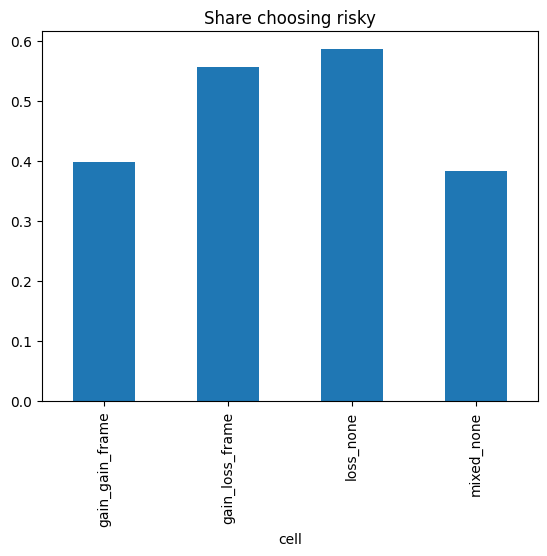

In [3]:
train = train.drop(columns=["realised_payout_inr"])

# a quick look at the data
train["cell"] = train.problem_domain + "_" + train.frame
print(train.groupby("cell").chose_risky.mean().round(3))
train.groupby("cell").chose_risky.mean().plot(kind="bar", title="Share choosing risky")
plt.show()

The same gain problems are chosen risky more often in the **loss frame** than the gain frame. The expected-value rule cannot see this, so frame should help.

## 3. Make new features
These are simple formulas using the problem numbers (nothing is learned from the data here).

In [4]:
def add_features(df):
    df = df.copy()
    # expected value of the risky option minus the sure amount
    df["ev_diff"] = df.prob_high * df.risky_high_inr + (1 - df.prob_high) * df.risky_low_inr - df.sure_amount_inr
    df["spread"] = df.risky_high_inr - df.risky_low_inr
    df["ev_ratio"] = df.ev_diff / df.spread                      # EV difference compared with the size of the stakes
    df["sure_pos"] = (df.sure_amount_inr - df.risky_low_inr) / df.spread
    df["small_p"] = (df.prob_high <= 0.10).astype(int)           # people overweight small probabilities
    df["large_p"] = (df.prob_high >= 0.90).astype(int)
    df["cell"] = df.problem_domain + "_" + df.frame
    # EV difference scaled by the endowment (stakes differ a lot between problems, this puts them on one scale)
    df["ev_end"] = df.ev_diff / (df.endowment_inr + 1)
    # Helper functions for prospect-theory features (Tversky & Kahneman 1992); the simulator is a prospect-theory model
    def pt_value(x, a, lam):                                       # value function, losses hurt lam times more
        return np.where(x >= 0, np.abs(x) ** a, -lam * np.abs(x) ** a)
    def pt_weight(p, g):                                           # probability weighting (small p overweighted)
        return p ** g / (p ** g + (1 - p) ** g) ** (1 / g)
    # prospect-theory value difference for 4 typical parameter sets (a, lam, g); fixed formulas, nothing learned from data
    for a, lam, g in [(0.88, 2.25, 0.61), (0.7, 1.5, 0.7), (0.88, 1.0, 0.8), (0.6, 2.5, 0.6)]:
        df["pt_%s_%s_%s" % (a, lam, g)] = (pt_weight(df.prob_high, g) * pt_value(df.risky_high_inr, a, lam)
                                           + pt_weight(1 - df.prob_high, g) * pt_value(df.risky_low_inr, a, lam)
                                           - pt_value(df.sure_amount_inr, a, lam)) / (df.endowment_inr + 1)   # uses outcomes AS SHOWN, so the frame effect is included
    df["paid"] = (df.session_type == "paid").astype(float)         # 0/1 version of session_type for the interactions below
    # ev_ratio separately for each domain/frame combination
    for c in ["gain_gain_frame", "gain_loss_frame", "loss_none", "mixed_none"]:
        df["ev_ratio_" + c] = df.ev_ratio * (df.cell == c)
        # The same split by domain/frame for every prospect-theory feature (value difference works differently in each cell)
        for p in [k for k in df.columns if k.startswith("pt_") and "gain_" not in k and "loss_" not in k and "mixed_" not in k]:
            df[p + "_" + c] = df[p] * (df.cell == c)
    # does the effect of the value difference depend on who is choosing? (value difference x person traits)
    for c in ["self_reported_risk_taking", "numeracy_score", "age_years", "time_pressure", "paid"]:
        df["evr_x_" + c] = df.ev_ratio * df[c]
        df["eve_x_" + c] = df.ev_end * df[c]
    return df

train = add_features(train)
test = add_features(test)

y = train.chose_risky
groups = train.participant_id

# groups of columns
nominal = ["prob_high", "risky_high_inr", "risky_low_inr", "sure_amount_inr"]
derived = ["ev_diff", "ev_ratio", "sure_pos", "spread", "small_p", "large_p"]
derived_new = derived + ["ev_end"] + [c for c in train.columns if c.startswith("pt_") and c.count("_") == 3]   # new list = old features + ev_end + prospect-theory features
frame_cols = ["problem_domain", "frame", "cell"]              # categories
person_cols = ["time_pressure", "numeracy_score", "age_years", "self_reported_risk_taking"]
interactions_old = [c for c in train.columns if c.startswith("ev_ratio_")]   # kept the original list so I can compare old vs new
interactions = [c for c in train.columns if c.startswith(("ev_ratio_", "evr_x_", "eve_x_")) or (c.startswith("pt_") and c.count("_") > 3)]   # now also includes pt x cell and value difference x trait interactions
C_FINAL = 0.1  # stronger L2 regularisation (the model has many more columns now); chosen with participant-grouped CV, 0.03 to 0.3 all gave the same AUC

## 4. Evaluation function
Every model is evaluated the same way: `GroupKFold` (a participant's 40 decisions always stay together). Scaling and one-hot encoding are inside the pipeline, so they are fitted on the training folds only.

In [5]:
results = []   # I save every run here

def make_model(clf, num_cols, cat_cols=[]):
    if len(cat_cols) > 0:
        prep = ColumnTransformer([("num", StandardScaler(), num_cols),
                                  ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)])
    else:
        prep = ColumnTransformer([("num", StandardScaler(), num_cols)])
    return make_pipeline(prep, clf)

def evaluate(name, model, cols, cv=None):
    if cv is None:
        cv = GroupKFold(n_splits=12)
    g = groups if isinstance(cv, GroupKFold) else None     # only GroupKFold needs the groups
    if hasattr(model, "predict_proba"):
        p = cross_val_predict(model, train[cols], y, cv=cv, groups=g, method="predict_proba")[:, 1]
        ll, acc = log_loss(y, p), accuracy_score(y, p > 0.5)
    else:                                  # SVM has no probabilities
        p = cross_val_predict(model, train[cols], y, cv=cv, groups=g, method="decision_function")
        ll, acc = np.nan, np.nan
    auc = roc_auc_score(y, p)
    results.append({"run": name, "auc": round(auc, 3), "log_loss": round(ll, 3), "accuracy": round(acc, 3), "n_features": len(cols)})
    print(f"{name:35s} AUC = {auc:.3f}")
    return p

## 5. Baselines
All use the 4 nominal columns and the same validation: a constant predictor, the expected-value rule, and four models from the lectures (logistic regression, LDA, Gaussian Naive Bayes, linear SVM).

In [6]:
# 1) constant (prior) predictor
evaluate("Baseline 1: constant", DummyClassifier(strategy="prior"), nominal)

# 2) expected-value rule: no training, just use ev_diff as the score
auc_ev = roc_auc_score(y, train.ev_diff)
results.append({"run": "Baseline 2: expected-value rule", "auc": round(auc_ev, 3), "log_loss": np.nan,
                "accuracy": round(accuracy_score(y, train.ev_diff > 0), 3), "n_features": 1})
print("Baseline 2: expected-value rule     AUC =", round(auc_ev, 3))

# 3-6) models on the 4 nominal columns
evaluate("Baseline 3: logistic regression", make_model(LogisticRegression(max_iter=1000), nominal), nominal)
evaluate("Baseline 4: LDA", make_model(LinearDiscriminantAnalysis(), nominal), nominal)
evaluate("Baseline 5: Gaussian Naive Bayes", make_model(GaussianNB(), nominal), nominal)
evaluate("Baseline 6: linear SVM", make_model(LinearSVC(max_iter=10000), nominal), nominal)

Baseline 1: constant                AUC = 0.458
Baseline 2: expected-value rule     AUC = 0.727
Baseline 3: logistic regression     AUC = 0.721
Baseline 4: LDA                     AUC = 0.716
Baseline 5: Gaussian Naive Bayes    AUC = 0.626
Baseline 6: linear SVM              AUC = 0.718


array([-0.32513797,  0.25282741, -0.03174315, ...,  1.0994615 ,
        0.19608638,  0.00851761], shape=(8400,))

**Observation:** The expected-value rule (about 0.727) is as good as any model that only sees the 4 raw numbers. This is because expected value is probability × outcome, which a linear model on the raw columns cannot build by itself. So the **features matter more than the model type**.

## 6. Experiment 1: which features help? (logistic regression)
I add one group of features at a time and compare AUC. Only the feature set changes.

In [18]:
exp1_a = evaluate("Exp1a: nominal only", make_model(LogisticRegression(max_iter=1000), nominal), nominal)
cols = nominal + derived
evaluate("Exp1b: + EV features", make_model(LogisticRegression(max_iter=1000), nominal + derived), cols)
cols = nominal + derived + frame_cols
evaluate("Exp1c: + domain and frame", make_model(LogisticRegression(max_iter=1000), nominal + derived, frame_cols), cols)
cols = nominal + derived + person_cols + frame_cols + ["session_type"]
evaluate("Exp1d: + person/context info", make_model(LogisticRegression(max_iter=1000), nominal + derived + person_cols, frame_cols + ["session_type"]), cols)
cols = nominal + derived + interactions_old + frame_cols                      
evaluate("Exp1e: + interactions (original)", make_model(LogisticRegression(max_iter=1000), nominal + derived + interactions_old, frame_cols), cols)
cols = nominal + derived_new + interactions + frame_cols                      
p_best = evaluate("Exp1f: + prospect-theory features (NEW final)", make_model(LogisticRegression(C=C_FINAL, max_iter=5000), nominal + derived_new + interactions, frame_cols), cols)   

Exp1a: nominal only                 AUC = 0.721
Exp1b: + EV features                AUC = 0.783
Exp1c: + domain and frame           AUC = 0.812
Exp1d: + person/context info        AUC = 0.810
Exp1e: + interactions (original)    AUC = 0.814
Exp1f: + prospect-theory features (NEW final) AUC = 0.817


**Result:** EV features give the biggest jump (0.72 to 0.78) and domain/frame add more (to 0.81). Person/context info does **not** help (it even drops slightly). The original interactions give a very small improvement (0.814). The prospect-theory features and trait interactions (Exp1f) add a little more (about 0.817), which is within fold noise but consistent across my checks. This matches my hypothesis: framing matters, and age/numeracy/risk score do not help for people the model has not seen. I will use the last model (1f) as my final model.

## 7. Experiment 2: random split vs participant split
Same model and features. Only the way I split the data changes.

In [ ]:
cols = nominal + derived_new + interactions + frame_cols                      
model = make_model(LogisticRegression(C=C_FINAL, max_iter=5000), nominal + derived_new + interactions, frame_cols)  
evaluate("Exp2: random split (KFold)", model, cols, cv=KFold(n_splits=8, shuffle=True, random_state=0))
evaluate("Exp2: participant split (GroupKFold)", model, cols)

# same test with a model that is allowed to use participant_id (it can "remember" a person)
train["pid"] = train.participant_id
model_id = make_model(LogisticRegression(C=C_FINAL, max_iter=5000), nominal + derived_new + interactions, frame_cols + ["pid"])   
evaluate("Exp2: + participant_id, random split", model_id, cols + ["pid"], cv=KFold(n_splits=8, shuffle=True, random_state=0))
evaluate("Exp2: + participant_id, group split", model_id, cols + ["pid"])

Exp2: random split (KFold)          AUC = 0.818
Exp2: participant split (GroupKFold) AUC = 0.817
Exp2: + participant_id, random split AUC = 0.840
Exp2: + participant_id, group split AUC = 0.817


array([0.71434574, 0.82023145, 0.47108163, ..., 0.92000462, 0.62189229,
       0.51622501], shape=(8400,))

**Result:** For this simple model the random split and the participant split give about the same AUC (0.817), so my hypothesis was only partly right: the random split is not optimistic here. But when the model can use `participant_id`, the random split gives a clearly higher AUC (about 0.84), while the participant split stays at 0.817. Knowing a person helps only if that person was in the training data. The test set has new people, so the participant split is the honest one.

## 8. Experiment 3: response time
`response_time_ms` is measured while the person decides, so it would not be known before the choice. I leave it out of my final model. I check if it would have helped anyway.

In [ ]:
cols = nominal + derived_new + interactions + frame_cols + ["response_time_ms"]   
evaluate("Exp3: final features + response time", make_model(LogisticRegression(C=C_FINAL, max_iter=10000), nominal + derived_new + interactions + ["response_time_ms"], frame_cols), cols)  
print(train.groupby("chose_risky").response_time_ms.mean().round(0))

Exp3: final features + response time AUC = 0.817
chose_risky
0    807.0
1    823.0
Name: response_time_ms, dtype: float64


It gives no improvement and the average time is almost the same for both choices, so leaving it out loses nothing.

## 9. ROC curve and uncertainty for the final model
The ROC curve shows the trade-off between catching risky choices (true positive rate) and false alarms (false positive rate) at every threshold. The area under it is the AUC. To see how stable the AUC is, I also compute it separately on each of the 5 participant folds.

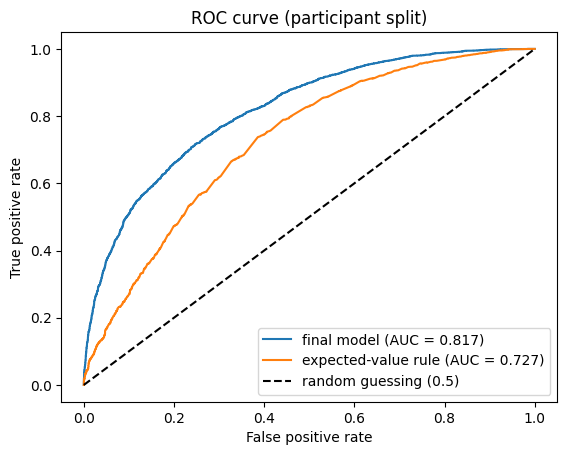

AUC per fold: [0.834 0.803 0.805 0.802 0.843]
Mean AUC = 0.817, standard deviation = 0.018


In [ ]:
final_cols = nominal + derived_new + interactions + frame_cols  

# ROC curve using the out-of-fold predictions of the final model
fpr, tpr, _ = roc_curve(y, p_best)
plt.plot(fpr, tpr, label="final model (AUC = %.3f)" % roc_auc_score(y, p_best))
fpr2, tpr2, _ = roc_curve(y, train.ev_diff)
plt.plot(fpr2, tpr2, label="expected-value rule (AUC = %.3f)" % roc_auc_score(y, train.ev_diff))
plt.plot([0, 1], [0, 1], "k--", label="random guessing (0.5)")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate"); plt.title("ROC curve (participant split)")
plt.legend(); plt.show()

# AUC on each fold separately -> mean and spread
fold_aucs = []
for train_idx, val_idx in GroupKFold(n_splits=5).split(train, y, groups):   
    m = make_model(LogisticRegression(C=C_FINAL, max_iter=5000), nominal + derived_new + interactions, frame_cols)  
    m.fit(train.iloc[train_idx][final_cols], y.iloc[train_idx])
    p = m.predict_proba(train.iloc[val_idx][final_cols])[:, 1]
    fold_aucs.append(roc_auc_score(y.iloc[val_idx], p))
print("AUC per fold:", np.round(fold_aucs, 3))
print("Mean AUC = %.3f, standard deviation = %.3f" % (np.mean(fold_aucs), np.std(fold_aucs)))

The final model's ROC curve lies clearly above the expected-value rule and the random line. The AUC changes only a little between folds (see the standard deviation above), so the result is fairly stable. With only 210 participants, differences of about 0.003 between models are within this noise, so I should not over-interpret them.

## 10. Calibration of the final model
Are the predicted probabilities close to the real share of risky choices?

C:\Users\Lenvo\AppData\Local\Temp\ipykernel_8268\314531695.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  check = pd.DataFrame({"predicted": p_best, "actual": y}).groupby(bins).mean()


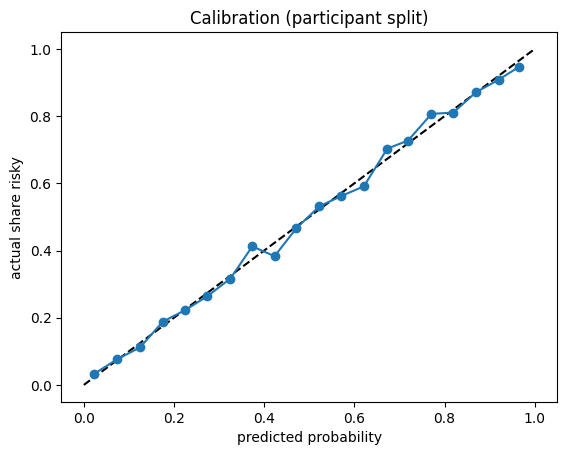

paid AUC = 0.847
hypothetical AUC = 0.791


In [11]:
bins = pd.cut(p_best, bins=20)
check = pd.DataFrame({"predicted": p_best, "actual": y}).groupby(bins).mean()
plt.plot([0, 1], [0, 1], "k--")
plt.plot(check.predicted, check.actual, "o-")
plt.xlabel("predicted probability"); plt.ylabel("actual share risky"); plt.title("Calibration (participant split)")
plt.show()

for s in ["paid", "hypothetical"]:
    m = (train.session_type == s).values
    print(s, "AUC =", round(roc_auc_score(y[m], p_best[m]), 3))

The points are close to the diagonal, so the probabilities are well calibrated. The model is more accurate in paid sessions (AUC about 0.85) than hypothetical ones (about 0.79).

## 11. Error analysis
Where does the model do well or badly, and how does it compare with the EV rule?

gain_gain_frame    model AUC = 0.680 | EV rule AUC = 0.632
gain_loss_frame    model AUC = 0.765 | EV rule AUC = 0.722
loss_none          model AUC = 0.784 | EV rule AUC = 0.733
mixed_none         model AUC = 0.898 | EV rule AUC = 0.858

Accuracy per participant: min 0.42 | mean 0.73 | max 0.98


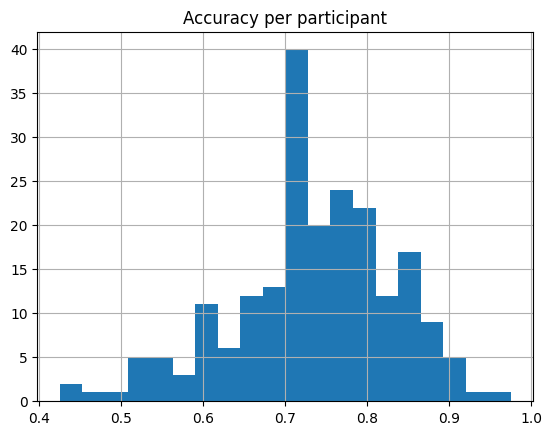

In [12]:
err = pd.DataFrame({"cell": train.cell, "y": y, "model": p_best, "ev": train.ev_diff})
for name, g in err.groupby("cell"):
    print(f"{name:18s} model AUC = {roc_auc_score(g.y, g.model):.3f} | EV rule AUC = {roc_auc_score(g.y, g.ev):.3f}")

# accuracy of each participant
err["person"] = groups
err["correct"] = ((err.model > 0.5) == err.y)
acc_person = err.groupby("person").correct.mean()
print("\nAccuracy per participant: min", acc_person.min().round(2), "| mean", acc_person.mean().round(2), "| max", acc_person.max().round(2))
acc_person.hist(bins=20)
plt.title("Accuracy per participant"); plt.show()

- The model beats the EV rule in every group.
- The hardest group is gain problems in the gain frame (AUC about 0.68); the easiest is mixed gambles (about 0.90).
- Accuracy depends a lot on the person (from about 0.42 to 0.92). The model cannot know if a new person is a strong risk-taker or a very careful one, so it does badly on extreme people.

## 12. Final model and submission file
I fit the final model once on all training data and predict the test file once.

In [ ]:
final_cols = nominal + derived_new + interactions + frame_cols   # CHANGED: new feature lists (prospect-theory + trait interactions)
final_model = make_model(LogisticRegression(C=C_FINAL, max_iter=5000), nominal + derived_new + interactions, frame_cols)   
final_model.fit(train[final_cols], y)

submission = pd.DataFrame({"decision_id": test.decision_id,
                           "chose_risky": final_model.predict_proba(test[final_cols])[:, 1]})

# check the format
assert list(submission.columns) == list(sample.columns)
assert len(submission) == len(sample)
assert set(submission.decision_id) == set(sample.decision_id)
assert submission.chose_risky.notna().all()

submission.to_csv("submission6.csv", index=False)
print(submission.shape)
submission.head()

(3600, 2)


,decision_id,chose_risky
0,B00001,0.405913
1,B00011,0.529323
2,B00012,0.374400
3,B00013,0.615876
4,B00014,0.515202


In [14]:
pd.DataFrame(results).to_csv("experimental_results6.csv", index=False)
pd.DataFrame(results)

,run,auc,log_loss,accuracy,n_features
0,Baseline 1: constant,0.458,0.693,0.518,4
1,Baseline 2: expected-value rule,0.727,NaN,0.664,1
2,Baseline 3: logistic regression,0.721,0.619,0.662,4
3,Baseline 4: LDA,0.716,0.620,0.657,4
4,Baseline 5: Gaussian Naive Bayes,0.626,0.687,0.590,4
5,Baseline 6: linear SVM,0.718,NaN,NaN,4
6,Exp1a: nominal only,0.721,0.619,0.662,4
7,Exp1b: + EV features,0.783,0.559,0.704,10
8,Exp1c: + domain and frame,0.812,0.529,0.733,13
9,Exp1d: + person/context info,0.810,0.530,0.729,18


## 13. Conclusion and limitations
**Answer:** For new participants, logistic regression with expected-value features, domain/frame and interactions gets AUC of about **0.82** (0.817 with prospect-theory features; 0.814 before), compared with 0.73 for the expected-value rule and about 0.72 for models using only the raw numbers. Framing helps; person details (age, numeracy, risk score) do not help for unseen people. A random split gave the same AUC for this simple model, but it becomes optimistic (0.84 vs 0.817) if the model can learn who the person is.

**Limitations**
- The data is **simulated**, so this says nothing about real people.
- Choices are random in the simulator, so a perfect score is impossible.
- Only 210 training participants, and I used one run of 5-fold CV (uncertainty is only the spread across 5 folds), so differences of about 0.003 should not be over-interpreted.
- I chose the final model using the same CV, so the estimate may be slightly optimistic.
- I show associations only, not causes.


In [15]:
train_features = train[["decision_id", "participant_id"] + final_cols].copy()
train_features["chose_risky"] = y.values
train_features.to_csv("final_features_train.csv", index=False)

test_features = test[["decision_id"] + final_cols].copy()
test_features.to_csv("final_features_test.csv", index=False)